
# Comparação de Arquiteturas — Classificação Mina/Não-Mina (Transfer Learning)

Este notebook treina e compara, sob as **mesmas condições** (mesmo split de dados, mesmo
`class_weight`, mesma augmentation, mesmo protocolo de fine-tuning), quatro backbones
pré-treinados diferentes:

| Backbone | Por que está na lista |
|---|---|
| **MobileNetV2** | O que você já usou — serve de baseline de comparação |
| **EfficientNetB0** | Representações geralmente melhores que MobileNetV2 com custo parecido — minha aposta como mais provável de melhorar o resultado |
| **ResNet50V2** | Mais parâmetros/capacidade — pode ajudar ou pode overfittar com poucos dados, por isso entra no teste |
| **DenseNet121** | Reaproveita features entre camadas (conexões densas) — costuma se sair bem em datasets pequenos/médios |

Cada backbone passa pelo mesmo protocolo de 2 fases (base congelada → fine-tuning) do seu
notebook anterior, com checkpoint separado de cada fase. No final, todos os melhores
checkpoints (um por backbone) são avaliados no mesmo conjunto de teste, e o notebook monta
uma tabela comparativa + escolhe automaticamente o vencedor geral.

> Aviso de tempo: treinar 4 backbones x 2 fases é bem mais demorado que treinar 1. Se quiser
> reduzir, edite o dicionário `BACKBONES` na célula de configuração e deixe só os que
> quiser testar.


In [1]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, precision_recall_curve,
    roc_auc_score, f1_score
)

import tensorflow as tf
from tensorflow.keras import layers, applications, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

print(f"TensorFlow Version: {tf.__version__}")


TensorFlow Version: 2.21.0


In [ ]:

# ============================ CONFIGURAÇÃO ============================
DATA_DIR = r'D:\testte\dataset'   # pastas 0_sem_minas / 1_com_minas dentro daqui
BATCH_SIZE = 32
IMG_SIZE = (96, 96)

EPOCHS_FASE1 = 20   # base congelada
EPOCHS_FASE2 = 10   # fine-tuning
FREEZE_FRACTION = 0.7  # fração inicial das camadas do backbone que ficam congeladas no fine-tuning
SOFTEN_FACTOR = 0.6     # suavização do class_weight (0=sem peso, 1=peso balanceado puro)
RECALL_MINIMO_DESEJADO = 0.85

os.makedirs("checkpoints", exist_ok=True)

# Backbones a comparar: nome -> (classe do Keras Applications, função de preprocess_input)
BACKBONES = {
    "MobileNetV2":    (applications.MobileNetV2,    applications.mobilenet_v2.preprocess_input),
    "EfficientNetB0": (applications.EfficientNetB0, applications.efficientnet.preprocess_input),
    "ResNet50V2":     (applications.ResNet50V2,      applications.resnet_v2.preprocess_input),
    "DenseNet121":    (applications.DenseNet121,     applications.densenet.preprocess_input),
}
print("Backbones a comparar:", list(BACKBONES.keys()))


Backbones a comparar: ['MobileNetV2', 'EfficientNetB0', 'ResNet50V2', 'DenseNet121']


## Carregamento dos dados (igual ao notebook anterior)

In [3]:

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.3, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='binary'
)
val_test_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.3, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='binary'
)

print("Classes encontradas:", train_dataset.class_names)
print("Se não for ['0_sem_minas', '1_com_minas'], renomeie as pastas antes de continuar.")

val_test_batches = tf.data.experimental.cardinality(val_test_dataset)
val_dataset = val_test_dataset.take(val_test_batches // 2)
test_dataset = val_test_dataset.skip(val_test_batches // 2)

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

print(f"Batches -> treino: {tf.data.experimental.cardinality(train_dataset).numpy()}, "
      f"validação: {tf.data.experimental.cardinality(val_dataset).numpy()}, "
      f"teste: {tf.data.experimental.cardinality(test_dataset).numpy()}")

data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal"),
  layers.RandomRotation(0.05),
  layers.RandomZoom(0.1),
  layers.RandomContrast(0.2),
], name="data_augmentation")


Found 1170 files belonging to 2 classes.
Using 819 files for training.
Found 1170 files belonging to 2 classes.
Using 351 files for validation.
Classes encontradas: ['0_sem_minas', '1_com_minas']
Se não for ['0_sem_minas', '1_com_minas'], renomeie as pastas antes de continuar.
Batches -> treino: 26, validação: 5, teste: 6


In [4]:

train_labels = np.concatenate([y for x, y in train_dataset], axis=0).flatten()
classes = np.unique(train_labels)
class_weights_array = compute_class_weight(class_weight='balanced', classes=classes, y=train_labels)
class_weights_raw = {int(classes[i]): float(class_weights_array[i]) for i in range(len(classes))}
class_weights = {c: 1.0 + SOFTEN_FACTOR * (w - 1.0) for c, w in class_weights_raw.items()}

print(f"Pesos 'puros':      {class_weights_raw}")
print(f"Pesos suavizados:   {class_weights}")


Pesos 'puros':      {0: 0.6204545454545455, 1: 2.5754716981132075}
Pesos suavizados:   {0: 0.7722727272727273, 1: 1.9452830188679244}


## Função genérica de construção de modelo (funciona para qualquer backbone da lista)

In [5]:

def build_model(backbone_name):
    base_cls, preprocess_fn = BACKBONES[backbone_name]

    base_model = base_cls(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
    base_model.trainable = False

    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = preprocess_fn(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs, name=backbone_name)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall'),
                 tf.keras.metrics.AUC(name='auc')]
    )
    return model, base_model


def evaluate_checkpoint(path, name, test_dataset):
    m = tf.keras.models.load_model(path)
    y_true = np.concatenate([y for x, y in test_dataset], axis=0).flatten()
    y_prob = m.predict(test_dataset, verbose=0).flatten()
    y_pred = (y_prob >= 0.5).astype(int)
    auc = roc_auc_score(y_true, y_prob)
    f1 = f1_score(y_true, y_pred)
    return {"name": name, "model_path": path, "y_true": y_true, "y_prob": y_prob,
            "auc": auc, "f1": f1}


## Loop principal: treina as 2 fases para cada backbone

In [6]:

all_results = []  # guarda o melhor resultado (fase congelada ou fine-tuned) de cada backbone

for backbone_name in BACKBONES:
    print(f"\n{'#'*70}\n### Backbone: {backbone_name}\n{'#'*70}")
    t0 = time.time()

    model, base_model = build_model(backbone_name)

    ckpt_frozen_path = f"checkpoints/{backbone_name}_fase_congelada.keras"
    ckpt_finetuned_path = f"checkpoints/{backbone_name}_fine_tuned.keras"

    early_stop = EarlyStopping(monitor='val_recall', patience=8, restore_best_weights=True, mode='max')
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)
    checkpoint_frozen = ModelCheckpoint(ckpt_frozen_path, monitor='val_auc', mode='max',
                                         save_best_only=True, verbose=0)

    print(f"[{backbone_name}] Fase 1 — base congelada...")
    model.fit(
        train_dataset, epochs=EPOCHS_FASE1, validation_data=val_dataset,
        class_weight=class_weights, callbacks=[early_stop, reduce_lr, checkpoint_frozen],
        verbose=0,
    )

    # Fine-tuning: descongela uma fração do backbone
    base_model.trainable = True
    freeze_until = int(len(base_model.layers) * FREEZE_FRACTION)
    for layer in base_model.layers[:freeze_until]:
        layer.trainable = False

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall'),
                 tf.keras.metrics.AUC(name='auc')]
    )

    checkpoint_finetuned = ModelCheckpoint(ckpt_finetuned_path, monitor='val_auc', mode='max',
                                            save_best_only=True, verbose=0)

    print(f"[{backbone_name}] Fase 2 — fine-tuning ({len(base_model.layers) - freeze_until} camadas destravadas)...")
    model.fit(
        train_dataset, epochs=EPOCHS_FASE2, validation_data=val_dataset,
        class_weight=class_weights, callbacks=[early_stop, reduce_lr, checkpoint_finetuned],
        verbose=0,
    )

    # Avalia as duas fases no teste e guarda a melhor
    r_frozen = evaluate_checkpoint(ckpt_frozen_path, f"{backbone_name} (congelada)", test_dataset)
    r_finetuned = evaluate_checkpoint(ckpt_finetuned_path, f"{backbone_name} (fine-tuned)", test_dataset)
    best_for_backbone = max([r_frozen, r_finetuned], key=lambda r: r["auc"])
    best_for_backbone["backbone"] = backbone_name
    best_for_backbone["tempo_s"] = round(time.time() - t0, 1)
    all_results.append(best_for_backbone)

    print(f"[{backbone_name}] Melhor fase: {best_for_backbone['name']} "
          f"(AUC={best_for_backbone['auc']:.4f}, F1={best_for_backbone['f1']:.4f}, "
          f"tempo={best_for_backbone['tempo_s']}s)")

    # Libera memória antes do próximo backbone
    del model, base_model
    tf.keras.backend.clear_session()



######################################################################
### Backbone: MobileNetV2
######################################################################
[MobileNetV2] Fase 1 — base congelada...


C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


[MobileNetV2] Fase 2 — fine-tuning (47 camadas destravadas)...
[MobileNetV2] Melhor fase: MobileNetV2 (congelada) (AUC=0.8980, F1=0.7872, tempo=153.1s)


######################################################################
### Backbone: EfficientNetB0
######################################################################
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
[EfficientNetB0] Fase 1 — base congelada...


C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


[EfficientNetB0] Fase 2 — fine-tuning (72 camadas destravadas)...
[EfficientNetB0] Melhor fase: EfficientNetB0 (congelada) (AUC=0.8614, F1=0.7500, tempo=179.3s)

######################################################################
### Backbone: ResNet50V2
######################################################################
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step
[ResNet50V2] Fase 1 — base congelada...


C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


[ResNet50V2] Fase 2 — fine-tuning (57 camadas destravadas)...
[ResNet50V2] Melhor fase: ResNet50V2 (congelada) (AUC=0.8579, F1=0.6024, tempo=288.3s)

######################################################################
### Backbone: DenseNet121
######################################################################
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
[DenseNet121] Fase 1 — base congelada...


C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


[DenseNet121] Fase 2 — fine-tuning (129 camadas destravadas)...
[DenseNet121] Melhor fase: DenseNet121 (fine-tuned) (AUC=0.8320, F1=0.6897, tempo=289.6s)


## Tabela comparativa final

      Backbone Melhor fase  AUC (teste)  F1 @0.5 (teste)  Precisão @0.5  Recall @0.5  Tempo (s)
   MobileNetV2   congelada       0.8980           0.7872         0.8810       0.7115      153.1
EfficientNetB0   congelada       0.8614           0.7500         0.8182       0.6923      179.3
    ResNet50V2   congelada       0.8579           0.6024         0.8065       0.4808      288.3
   DenseNet121  fine-tuned       0.8320           0.6897         0.6250       0.7692      289.6


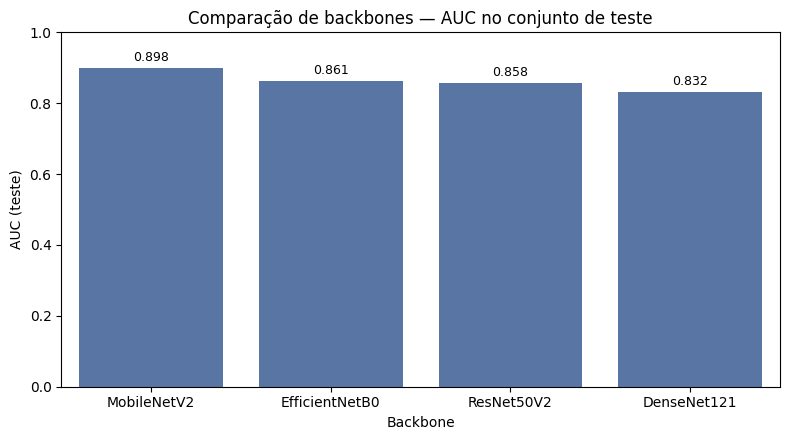

,Backbone,Melhor fase,AUC (teste),F1 @0.5 (teste),Precisão @0.5,Recall @0.5,Tempo (s)
0,MobileNetV2,congelada,0.8980,0.7872,0.8810,0.7115,153.1
1,EfficientNetB0,congelada,0.8614,0.7500,0.8182,0.6923,179.3
2,ResNet50V2,congelada,0.8579,0.6024,0.8065,0.4808,288.3
3,DenseNet121,fine-tuned,0.8320,0.6897,0.6250,0.7692,289.6


In [7]:

summary_rows = []
for r in all_results:
    y_pred_05 = (r["y_prob"] >= 0.5).astype(int)
    from sklearn.metrics import precision_score, recall_score
    summary_rows.append({
        "Backbone": r["backbone"],
        "Melhor fase": r["name"].split("(")[-1].replace(")", "").strip(),
        "AUC (teste)": round(r["auc"], 4),
        "F1 @0.5 (teste)": round(r["f1"], 4),
        "Precisão @0.5": round(precision_score(r["y_true"], y_pred_05), 4),
        "Recall @0.5": round(recall_score(r["y_true"], y_pred_05), 4),
        "Tempo (s)": r["tempo_s"],
    })

summary_df = pd.DataFrame(summary_rows).sort_values("AUC (teste)", ascending=False).reset_index(drop=True)
print(summary_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=summary_df, x="Backbone", y="AUC (teste)", ax=ax, color="#4C72B0")
ax.set_ylim(0, 1)
ax.set_title("Comparação de backbones — AUC no conjunto de teste")
for i, v in enumerate(summary_df["AUC (teste)"]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

summary_df



## Ajuste de threshold para o melhor backbone geral

Mesma lógica do notebook anterior: usa o backbone/fase vencedor pelo AUC no teste e sugere
o threshold que maximiza F1 e o threshold que garante o recall mínimo desejado.


>>> Vencedor geral: MobileNetV2 (congelada) (AUC=0.8980) <<<
Threshold que maximiza F1: 0.476 (precisão=0.886, recall=0.750)
Threshold para recall >= 0.85: 0.362 (precisão=0.577, recall=0.865)


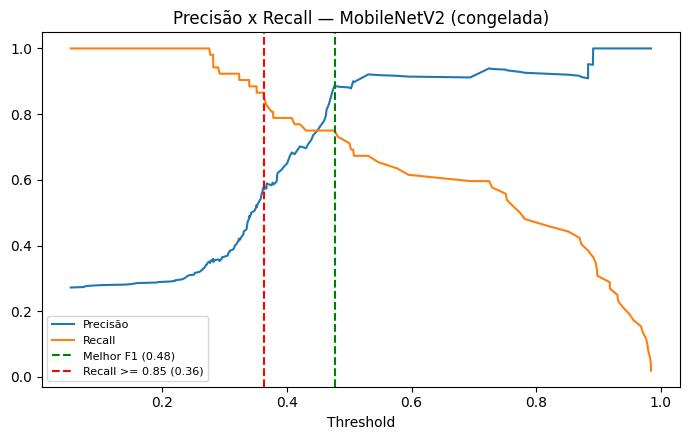


Relatório final (threshold otimizado por F1):
              precision    recall  f1-score   support

   Fundo (0)       0.91      0.96      0.94       139
    Mina (1)       0.89      0.75      0.81        52

    accuracy                           0.91       191
   macro avg       0.90      0.86      0.87       191
weighted avg       0.90      0.91      0.90       191



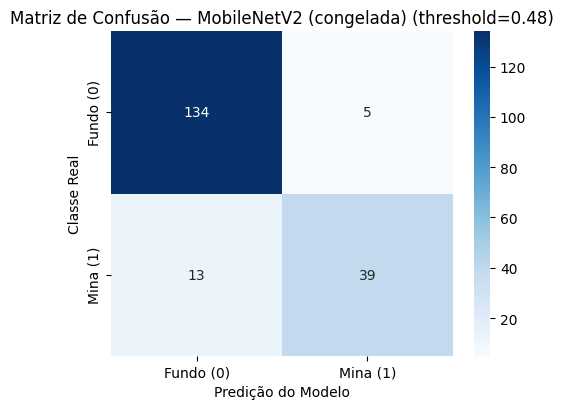

In [8]:

overall_best = max(all_results, key=lambda r: r["auc"])
print(f">>> Vencedor geral: {overall_best['name']} (AUC={overall_best['auc']:.4f}) <<<")

y_true = overall_best["y_true"]
y_prob = overall_best["y_prob"]

precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
best_f1_idx = np.argmax(f1_scores)
threshold_f1 = thresholds[best_f1_idx]

valid_idx = np.where(recalls[:-1] >= RECALL_MINIMO_DESEJADO)[0]
if len(valid_idx) > 0:
    best_recall_idx = valid_idx[np.argmax(precisions[:-1][valid_idx])]
    threshold_recall_alvo = thresholds[best_recall_idx]
else:
    threshold_recall_alvo = None
    print(f"Nenhum threshold atinge recall >= {RECALL_MINIMO_DESEJADO} para este modelo.")

print(f"Threshold que maximiza F1: {threshold_f1:.3f} "
      f"(precisão={precisions[best_f1_idx]:.3f}, recall={recalls[best_f1_idx]:.3f})")
if threshold_recall_alvo is not None:
    print(f"Threshold para recall >= {RECALL_MINIMO_DESEJADO}: {threshold_recall_alvo:.3f} "
          f"(precisão={precisions[best_recall_idx]:.3f}, recall={recalls[best_recall_idx]:.3f})")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thresholds, precisions[:-1], label="Precisão")
ax.plot(thresholds, recalls[:-1], label="Recall")
ax.axvline(threshold_f1, color="green", linestyle="--", label=f"Melhor F1 ({threshold_f1:.2f})")
if threshold_recall_alvo is not None:
    ax.axvline(threshold_recall_alvo, color="red", linestyle="--",
               label=f"Recall >= {RECALL_MINIMO_DESEJADO} ({threshold_recall_alvo:.2f})")
ax.set_xlabel("Threshold")
ax.set_title(f"Precisão x Recall — {overall_best['name']}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

y_pred_final = (y_prob >= threshold_f1).astype(int)
print("\nRelatório final (threshold otimizado por F1):")
print(classification_report(y_true, y_pred_final, target_names=['Fundo (0)', 'Mina (1)']))

cm = confusion_matrix(y_true, y_pred_final)
plt.figure(figsize=(5, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fundo (0)', 'Mina (1)'], yticklabels=['Fundo (0)', 'Mina (1)'])
plt.ylabel('Classe Real')
plt.xlabel('Predição do Modelo')
plt.title(f'Matriz de Confusão — {overall_best["name"]} (threshold={threshold_f1:.2f})')
plt.tight_layout()
plt.show()


## Salvando o modelo campeão

In [9]:

final_path = "checkpoints/modelo_campeao_geral.keras"
best_model_loaded = tf.keras.models.load_model(overall_best["model_path"])
best_model_loaded.save(final_path)

print(f"Modelo campeão: {overall_best['name']}")
print(f"Salvo em: {final_path}")
print(f"Threshold recomendado: {threshold_f1:.3f}")


Modelo campeão: MobileNetV2 (congelada)
Salvo em: checkpoints/modelo_campeao_geral.keras
Threshold recomendado: 0.476
